# DBSCAN – Density-Based Spatial Clustering of Applications with Noise

In [10]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [11]:
# Generate three dense clusters plus scattered outliers
np.random.seed(42)

# 300 clustered points in 3 blobs
X_blobs, _ = make_blobs(n_samples=300, centers=[(0, 0), (5, 5), (0, 5)],
                        cluster_std=0.6, random_state=42)

# 20 uniform outliers scattered in the empty space
X_noise = np.random.uniform(low=-3, high=8, size=(20, 2))

# Combine into one dataset
X_all = np.vstack([X_blobs, X_noise])

# Build DataFrame
df = pd.DataFrame(X_all, columns=["feature1", "feature2"])
print(df.shape)
print(df.head())

(320, 2)
   feature1  feature2
0 -0.714782  0.393932
1 -0.326630  0.066554
2  0.072177  5.308663
3  4.411095  5.277262
4  0.034925 -0.685782


In [12]:
# Scale features and run DBSCAN
# Scaling is mandatory because eps is distance-based
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["feature1", "feature2"]])

# Apply DBSCAN: eps = neighborhood radius, min_samples = density threshold
db = DBSCAN(eps=0.5, min_samples=5)
labels = db.fit_predict(X_scaled)

# Label -1 means noise / outlier
df["cluster"] = labels
df["is_outlier"] = df["cluster"] == -1

print(f"Detected outliers: {df['is_outlier'].sum()}")
print(df[df["is_outlier"]].head(10))

Detected outliers: 10
     feature1  feature2  cluster  is_outlier
300  1.119941  7.457857       -1        True
303 -2.361080  6.527938       -1        True
305 -2.773571  7.669008       -1        True
306  6.156869 -0.664270       -1        True
310  3.730382 -1.465568       -1        True
314  3.516560 -2.489045       -1        True
315  3.682993 -1.124235       -1        True
316 -2.284432  7.437741       -1        True
317  7.621952  5.892371       -1        True
319  4.526563  1.841677       -1        True


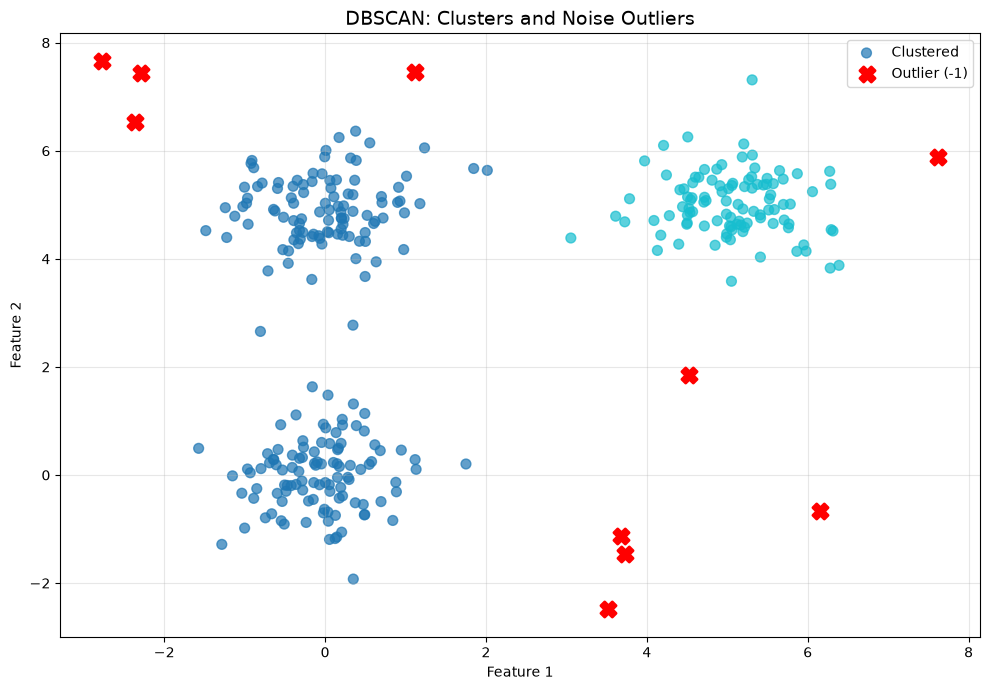

In [13]:
# Visualize clusters and DBSCAN outliers
plt.figure(figsize=(10, 7))

# Plot normal points colored by their cluster id
normal = df[~df["is_outlier"]]
plt.scatter(normal["feature1"], normal["feature2"], c=normal["cluster"],
            cmap="tab10", alpha=0.7, s=50, label="Clustered")

# Highlight noise points with red X markers
outliers = df[df["is_outlier"]]
plt.scatter(outliers["feature1"], outliers["feature2"], color="red",
            marker="X", s=120, linewidths=2, label="Outlier (-1)", zorder=5)

plt.title("DBSCAN: Clusters and Noise Outliers", fontsize=14)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

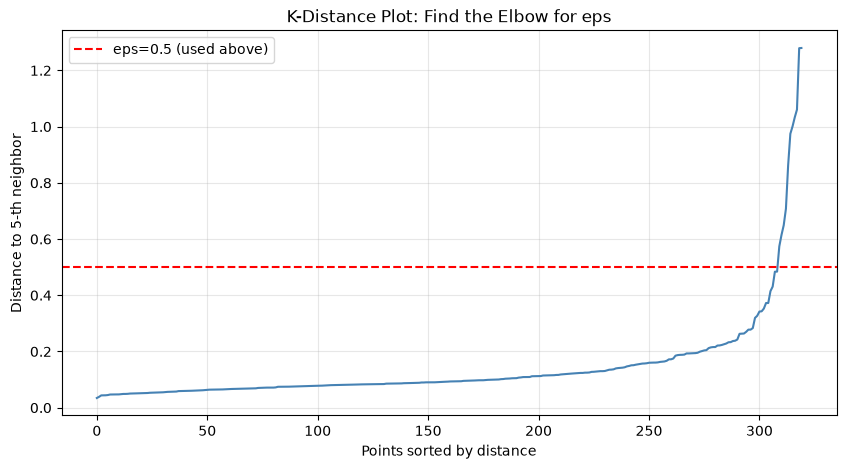

eps=0.3: 16 outliers, 304 clustered
eps=0.5: 10 outliers, 310 clustered
eps=0.8: 4 outliers, 316 clustered
eps=1.2: 0 outliers, 320 clustered


In [14]:
# Experiment - find best eps with k-distance elbow plot
k = 5  # Same as min_samples

# Compute distance to k-th nearest neighbor for each point
nbrs = NearestNeighbors(n_neighbors=k).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)

# Sort k-th distances to find the elbow
k_distances = np.sort(distances[:, k-1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances, color="steelblue")
plt.axhline(0.5, color="red", linestyle="--", label="eps=0.5 (used above)")
plt.title("K-Distance Plot: Find the Elbow for eps")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {k}-th neighbor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Try different eps values and compare counts
for e in [0.3, 0.5, 0.8, 1.2]:
    lbl = DBSCAN(eps=e, min_samples=5).fit_predict(X_scaled)
    print(f"eps={e}: {(lbl == -1).sum()} outliers, {(lbl != -1).sum()} clustered")
# Question: What happens when eps is too small or too large?